# 09 · Motor de cupo y pricing

Para cada cliente, el motor simula una grilla de **montos × tasas** y calcula la utilidad esperada de cada combinación con los modelos de las sesiones anteriores (decisión 012):

| Pieza | Modelo | Reacciona a |
|---|---|---|
| PD | Campeón LightGBM recalibrado | El **monto** (vía `monto_ingreso`) |
| Rendimiento si sale bueno | Supervivencia (prepago) | La **tasa**: más tasa, más intereses y más prepago |
| Pérdida si sale malo | Pérdida económica | La **tasa** |

    ROI esperado = (1 − PD) × r_bueno + PD × r_malo      · capacidad de pago: cuota ≤ 20% del ingreso

**Salidas (decisión 013):**
- **Monto máximo:** el mayor monto con utilidad > 0 que cumple la capacidad de pago.
- **Tasa de equilibrio:** ROI ≥ 0%; por debajo se pierde dinero (piso de rechazo).
- **Tasa sugerida:** ROI ≥ 4%; cubre el fondeo y la operación, que la utilidad bruta no descuenta.

**Referencias** (regresiones): el monto que pediría el cliente (demanda) y la tasa que cobraría Lending Club (mercado).

**Supuestos:** la PD no reacciona a la tasa (el modelo de riesgo no usa `int_rate`, decisión 001) y no hay datos de aceptación (precio sin elasticidad). Código: `src/credit_lab/motor.py` y `referencias.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from credit_lab.poblacion import cargar_poblacion
from credit_lab.motor import Motor, _expandir, monto_maximo_lote, TASAS, ROI_OBJETIVO
from credit_lab.prepago import rendimiento

pd.set_option("display.float_format", "{:,.4f}".format)
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

motor = Motor()
ref_monto = joblib.load("../modelos/referencia_monto.joblib")
ref_tasa = joblib.load("../modelos/referencia_tasa.joblib")
df = cargar_poblacion()
oot = df[df["muestra"].eq("oot")]
s2 = oot[oot["issue_d"].dt.month > 6]
pd_s2 = motor.campeon.pd(s2)

## 1. Un cliente por dentro: el mapa monto × tasa

,recomendación
monto_pedido,"9,250.0000"
tasa_ofrecida,16.9900
pd,0.2599
roi_esperado,0.0959
utilidad_esperada,887.3198
cuota_ingreso,0.0989
monto_maximo,"18,000.0000"
tasa_equilibrio,8.5000
tasa_sugerida,12.5000


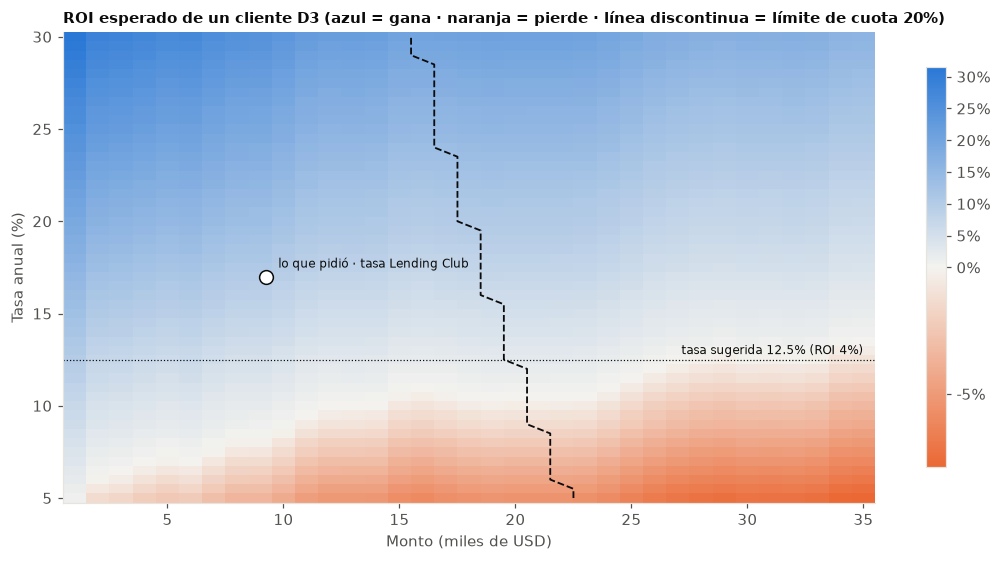

In [2]:
cliente = s2.loc[[s2.index[np.argsort(pd_s2)[int(0.9 * len(s2))]]]]
sim = motor.simular(cliente)
reco = motor.recomendar(cliente)

mapa = sim.pivot(index="tasa", columns="monto", values="roi_esperado")
capacidad = sim.pivot(index="tasa", columns="monto", values="cumple_capacidad")
divergente = LinearSegmentedColormap.from_list("div", [NARANJA, "#f4f3ef", AZUL])
fig, ax = plt.subplots(figsize=(10, 5.2))
im = ax.imshow(mapa.values, origin="lower", aspect="auto", cmap=divergente,
               norm=TwoSlopeNorm(vmin=mapa.values.min(), vcenter=0, vmax=mapa.values.max()),
               extent=[mapa.columns.min() / 1000 - 0.5, mapa.columns.max() / 1000 + 0.5, mapa.index.min() - 0.25, mapa.index.max() + 0.25])
ax.contour(mapa.columns / 1000, mapa.index, capacidad.values.astype(float), levels=[0.5], colors=TINTA, linewidths=1.2, linestyles="--")
ax.plot(reco["monto_pedido"] / 1000, reco["tasa_ofrecida"], "o", color="white", markersize=9, markeredgecolor=TINTA)
ax.annotate("lo que pidió · tasa Lending Club", (reco["monto_pedido"] / 1000, reco["tasa_ofrecida"]), xytext=(8, 6), textcoords="offset points", fontsize=8, color=TINTA)
ax.axhline(reco["tasa_sugerida"], color=TINTA, linewidth=0.8, linestyle=":")
ax.text(mapa.columns.max() / 1000, reco["tasa_sugerida"] + 0.3, f"tasa sugerida {reco['tasa_sugerida']:.1f}% (ROI 4%)", ha="right", fontsize=8, color=TINTA)
ax.grid(False)
ax.set_xlabel("Monto (miles de USD)")
ax.set_ylabel("Tasa anual (%)")
ax.set_title(f"ROI esperado de un cliente {cliente['sub_grade'].iloc[0]} (azul = gana · naranja = pierde · línea discontinua = límite de cuota 20%)", fontsize=10)
fig.colorbar(im, ax=ax, format=lambda v, _: f"{v:.0%}", shrink=0.85)
fig.tight_layout()
pd.Series(reco).to_frame("recomendación")

## 2. Cuatro clientes, de menor a mayor riesgo

In [3]:
filas = {}
for q, nombre in [(0.10, "Riesgo bajo (p10)"), (0.50, "Típico (p50)"), (0.90, "Riesgo alto (p90)"), (0.99, "Muy alto (p99)")]:
    c1 = s2.loc[[s2.index[np.argsort(pd_s2)[int(q * len(s2))]]]]
    r = motor.recomendar(c1)
    filas[nombre] = {"subgrado": c1["sub_grade"].iloc[0], "pd": r["pd"], "monto_pedido": r["monto_pedido"],
                     "monto_que_pediría (ref.)": ref_monto.predecir(c1)[0], "monto_máximo": r["monto_maximo"],
                     "tasa_Lending_Club": r["tasa_ofrecida"], "tasa_mercado (ref.)": ref_tasa.predecir(c1)[0],
                     "tasa_equilibrio": r["tasa_equilibrio"], "tasa_sugerida": r["tasa_sugerida"],
                     "roi_esperado_a_tasa_LC": r["roi_esperado"], "cuota/ingreso": r["cuota_ingreso"]}
pd.DataFrame(filas).T

,subgrado,pd,monto_pedido,monto_que_pediría (ref.),monto_máximo,tasa_Lending_Club,tasa_mercado (ref.),tasa_equilibrio,tasa_sugerida,roi_esperado_a_tasa_LC,cuota/ingreso
Riesgo bajo (p10),A4,0.0517,"7,550.0000","10,409.3265","32,000.0000",7.2600,10.3395,5.0000,5.0000,0.0736,0.0468
Típico (p50),B1,0.1295,"18,000.0000","19,304.2117","35,000.0000",8.1800,10.6310,5.0000,6.5000,0.0628,0.0848
Riesgo alto (p90),D3,0.2599,"9,250.0000","6,579.7488","18,000.0000",16.9900,16.6764,8.5000,12.5000,0.0959,0.0989
Muy alto (p99),E4,0.3866,"5,000.0000","4,821.8842","3,000.0000",19.9900,18.7316,23.0000,29.0000,-0.0186,0.0446


## 3. Regresiones de referencia (2015)

| Regresión | MAE | RMSE | R² |
|---|---|---|---|
| Monto que pediría el cliente | USD 4.462 | USD 5.938 | 0,46 |
| Tasa que cobraría Lending Club | 2,6 pts | 3,2 pts | **0,24** |

Nuestras variables explican solo el 24% del precio de Lending Club: ellos tenían información de buró que no está en los datos públicos y ajustaban sus tablas de tasas en el tiempo. Es una referencia útil, pero imperfecta.

## 4. Backtest: ¿las señales del motor anticipan la utilidad real?

No se puede observar qué habría pasado con otra tasa u otro monto, pero sí si las señales del motor **separan** préstamos que rindieron distinto. Muestra: 10.000 préstamos de jul–dic 2015, que ningún modelo vio.

In [4]:
muestra = s2.sample(10_000, random_state=0)
g = _expandir(muestra, "int_rate", TASAS)
ev = motor.evaluar(g.drop(columns="_prestamo"))
roi_g, tasa_g, idx = ev["roi_esperado"].to_numpy(), g["int_rate"].to_numpy(), g["_prestamo"].to_numpy()
r = rendimiento(muestra).to_numpy()
F = muestra["funded_amnt"].to_numpy()
y = muestra["malo"].to_numpy()
lc = muestra["int_rate"].to_numpy()
roi_real = lambda m: (r * F)[m].sum() / F[m].sum()

def tasa_min(objetivo):
    return pd.Series(np.where(roi_g >= objetivo, tasa_g, np.inf)).groupby(idx).min().replace(np.inf, np.nan).to_numpy()

sens = {}
for obj in [0.0, 0.02, 0.03, 0.04, 0.05]:
    t = tasa_min(obj)
    sub = lc < t
    sens[f"ROI objetivo {obj:.0%}"] = {"tasa_mínima_mediana": np.nanmedian(t), "tasa_mínima_p90": np.nanpercentile(t, 90),
                                       "% en el piso de 5%": np.mean(t == 5.0), "% que LC cobró por debajo": sub.mean(),
                                       "ROI real de esos": roi_real(sub), "ROI real del resto": roi_real(~sub), "mora de esos": y[sub].mean()}
pd.DataFrame(sens).T.style.format("{:.1%}").format("{:.1f}%", subset=["tasa_mínima_mediana", "tasa_mínima_p90"]) \
    .set_caption("Sensibilidad del pricing al ROI objetivo · el elegido es 4% (decisión 013)")

,tasa_mínima_mediana,tasa_mínima_p90,% en el piso de 5%,% que LC cobró por debajo,ROI real de esos,ROI real del resto,mora de esos
ROI objetivo 0%,5.0%,9.0%,66.3%,3.1%,-0.6%,6.1%,29.8%
ROI objetivo 2%,5.5%,11.5%,44.5%,7.0%,0.8%,6.3%,25.0%
ROI objetivo 3%,6.5%,12.5%,31.0%,10.7%,2.0%,6.4%,21.9%
ROI objetivo 4%,7.5%,13.5%,17.8%,16.3%,2.8%,6.5%,19.2%
ROI objetivo 5%,8.0%,14.5%,5.8%,25.8%,3.7%,6.6%,16.5%


,préstamos,ROI real,mora
LC cobró por debajo,1635,0.0278,0.1920
0–3 pts de más,4111,0.0666,0.1022
3–6 pts de más,2715,0.0683,0.1562
> 6 pts de más,1513,0.0569,0.1857


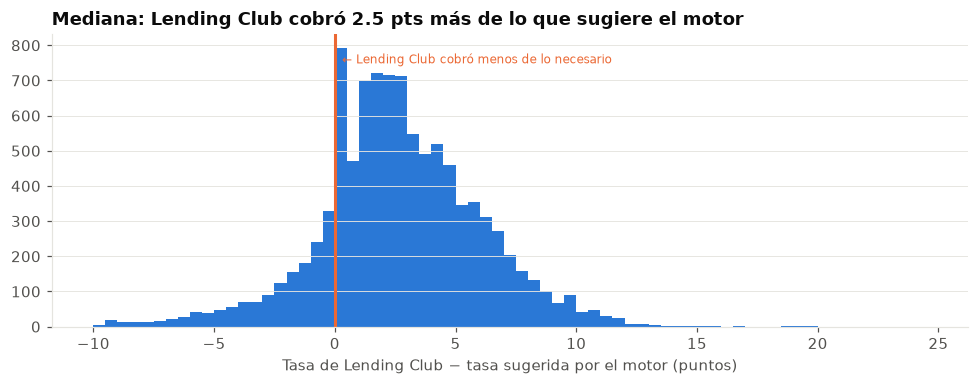

In [5]:
t4 = tasa_min(ROI_OBJETIVO)
brecha = lc - t4
grupos = pd.cut(brecha, [-30, 0, 3, 6, 30], labels=["LC cobró por debajo", "0–3 pts de más", "3–6 pts de más", "> 6 pts de más"])
tabla_brecha = pd.DataFrame({"préstamos": pd.Series(r).groupby(grupos).size(),
                             "ROI real": pd.Series(r * F).groupby(grupos).sum() / pd.Series(F).groupby(grupos).sum(),
                             "mora": pd.Series(y).groupby(grupos).mean()})

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(brecha[~np.isnan(brecha)], bins=np.arange(-10, 25, 0.5), color=AZUL)
ax.axvline(0, color=NARANJA, linewidth=2)
ax.text(0.3, ax.get_ylim()[1] * 0.9, "← Lending Club cobró menos de lo necesario", color=NARANJA, fontsize=8)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Tasa de Lending Club − tasa sugerida por el motor (puntos)")
ax.set_title(f"Mediana: Lending Club cobró {np.nanmedian(brecha):.1f} pts más de lo que sugiere el motor")
fig.tight_layout()
tabla_brecha

**Lectura:** la mayoría de los clientes pagó más de lo que su riesgo requería: hay espacio para ofrecer mejores tasas a los buenos clientes y quitárselos a la competencia. Los que Lending Club cobró **por debajo** de la tasa sugerida rindieron mucho menos y cayeron más: el motor los detecta.

**Un hallazgo que confirma un supuesto:** los préstamos cobrados **más de 6 puntos por encima** de la tasa sugerida rinden *menos* (5,7%) que los de 3–6 puntos (6,8%) y tienen más mora (18,6% vs 15,6%). Cobrar de más no sale gratis: una tasa muy alta sube la cuota y atrae o empuja a la mora. Es justo lo que el motor no captura, porque la PD no reacciona a la tasa (decisión 001). Mejora futura: un modelo de PD que incluya la tasa ofrecida, entrenado con cuidado para no copiar el score de Lending Club.

In [6]:
mmax = monto_maximo_lote(motor, muestra)
pide_mas = muestra["loan_amnt"].to_numpy() > mmax
pd.DataFrame({"préstamos": [(~pide_mas).sum(), pide_mas.sum()], "ROI real": [roi_real(~pide_mas), roi_real(pide_mas)],
              "mora": [y[~pide_mas].mean(), y[pide_mas].mean()]},
             index=["pidió ≤ monto máximo", "pidió > monto máximo"]).style.format({"préstamos": "{:,.0f}", "ROI real": "{:.1%}", "mora": "{:.1%}"}) \
    .set_caption("Backtest del cupo: préstamos que pidieron más de lo que el motor habría prestado")

,préstamos,ROI real,mora
pidió ≤ monto máximo,"9,643",6.1%,13.9%
pidió > monto máximo,357,1.8%,30.3%


---
## ✍️ Conclusiones de Neider

1. Con los modelos que ya tenía armé un motor que simula monto × tasa para cada cliente: la PD cambia con el monto y el prepago y la pérdida con la tasa. Así sale el monto máximo y la tasa mínima rentable, con capacidad de pago de cuota ≤ 20% del ingreso.
2. El motor se valida con dinero real: los préstamos que Lending Club cobró por debajo de la tasa sugerida rindieron 2,8% contra 6,7% del resto, y los que pidieron más del monto máximo rindieron 1,8% contra 6,1%, con el doble de mora.
3. La mayoría de los clientes pagó más de lo que su riesgo pedía (mediana 2,5 pts): hay espacio para ofrecer mejores tasas a los buenos clientes. Pero cobrar demasiado tampoco sirve: con más de 6 pts de sobreprecio sube la mora, algo que mi PD todavía no captura.
4. Las regresiones de monto y tasa sirven como referencia, no para decidir: replican la demanda del cliente y el precio de Lending Club, y nuestras variables solo explican el 24% de ese precio.